## Genomic RNA and replicase diffusion analysis

### Import libraries and define functions

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import ptitprince as pt
import seaborn as sns
import pandas as pd
from pandas import DataFrame
import os
import itertools
%matplotlib inline

def arrange_axis():
    sns.set_style('ticks')
    plt.grid(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().yaxis.set_ticks_position('left')
    plt.gca().xaxis.set_ticks_position('bottom')

### Data processing and merging

In [3]:
# Directories for three independent datasets
dir_a = 'RNA_Replicase_diffusion_data/260917_1 ImageJ/'
dir_b = 'RNA_Replicase_diffusion_data/260917_2 ImageJ/'
dir_c = 'RNA_Replicase_diffusion_data/260917_3 ImageJ/'
dir_back_a = 'RNA_Replicase_diffusion_data/260917_1 ImageJ_background/' # Background
dir_back_b = 'RNA_Replicase_diffusion_data/260917_2 ImageJ_background/' # Background
dir_back_c = 'RNA_Replicase_diffusion_data/260917_3 ImageJ_background/' # Background
dates_N3 = ['260917_1', '260917_2', '260917_3']

# Mapping experimental names to conditions
Names = {'#1-0h':'Ori_0h', '#1-2h':'Ori_2h', '#2-0h':'New_0h', '#2-2h':'New_2h'}

dAlls = []
dirs = [dir_a, dir_b, dir_c]
dirs_back = [dir_back_a, dir_back_b, dir_back_c]

for j in range(3):
    dir1 = dirs[j]
    dir1_back = dirs_back[j]
    samples = sorted(os.listdir(dir1))
    new_ds = []
    date = dates_N3[j]
    for i in range(len(samples)):
        dir2 = dir1 + samples[i]
        dir2_back = dir1_back + samples[i]
        files = sorted(os.listdir(dir2 + '/Result'))
        files_back = sorted(os.listdir(dir2_back + '/Result'))
        
        assert files == files_back, "Data and background filenames do not match"
        
        ds_set = [pd.read_csv(dir2 + '/Result/' + f) for f in files]
        ds_set_back = [pd.read_csv(dir2_back + '/Result/' + f) for f in files_back]
        
        # Number of droplets in each ImageJ results file
        Ns = [len(d)//4 for d in ds_set]
        
        # Extract fluorescence measurements for each channel
        special_channel_order = (date == '260917_1') and (samples[i].startswith('#1'))
        if special_channel_order:
            # Different channel order for the #1 dataset in 260917_1
            ds_set_FAM = [d[N:N*2] for d,N in zip(ds_set, Ns)]  # CH1: fluorescein
            ds_set_Alexa = [d[N*3:N*4] for d,N in zip(ds_set, Ns)] # CH3: Alexa Fluor 647
            ds_set_Cy3 = [d[N*2:N*3] for d,N in zip(ds_set, Ns)] # CH2: Cy3
        else:
            # Standard channel order
            ds_set_FAM = [d[N*3:N*4] for d,N in zip(ds_set, Ns)] # CH3: fluorescein
            ds_set_Alexa = [d[N*2:N*3] for d,N in zip(ds_set, Ns)] # CH2: Alexa Fluor 647
            ds_set_Cy3 = [d[N:N*2] for d,N in zip(ds_set, Ns)] # CH1: Cy3
        
        ds_set_FAM2 = []
        ds_set_Alexa2 = []
        ds_set_Cy32 = []
        
        # Calculate background intensity separately for each image
        for k in range(len(ds_set_FAM)):
            d_FAM = ds_set_FAM[k]
            d_Alexa = ds_set_Alexa[k]
            d_Cy3 = ds_set_Cy3[k]
            d_back = ds_set_back[k]
            # Droplet areas are identical across channels
            Area = np.array(d_FAM['Area'])
            Area_back = d_back['Area'].iloc[0]
            
            FAM = np.array(d_FAM['Mean'])
            Alexa = np.array(d_Alexa['Mean'])
            Cy3 = np.array(d_Cy3['Mean'])
            
            if special_channel_order:
                # Different channel order for the #1 dataset in 260917_1
                FAM_back = (Area_back*d_back['Mean'].iloc[0] - np.sum(FAM*Area)) / (Area_back - np.sum(Area))
                Alexa_back = (Area_back*d_back['Mean'].iloc[2] - np.sum(Alexa*Area)) / (Area_back - np.sum(Area))
                Cy3_back = (Area_back*d_back['Mean'].iloc[1] - np.sum(Cy3*Area)) / (Area_back - np.sum(Area))        
            else:
                FAM_back = (Area_back*d_back['Mean'].iloc[2] - np.sum(FAM*Area)) / (Area_back - np.sum(Area))
                Alexa_back = (Area_back*d_back['Mean'].iloc[1] - np.sum(Alexa*Area)) / (Area_back - np.sum(Area))
                Cy3_back = (Area_back*d_back['Mean'].iloc[0] - np.sum(Cy3*Area)) / (Area_back - np.sum(Area))
            
            # Add background values to the DataFrames
            d1, d2, d3 = ds_set_FAM[k].copy(), ds_set_Alexa[k].copy(), ds_set_Cy3[k].copy()
            d1['FAM_b'], d2['Alexa_b'], d3['Cy3_b'] = [FAM_back]*Ns[k], [Alexa_back]*Ns[k], [Cy3_back]*Ns[k]
            ds_set_FAM2.append(d1)
            ds_set_Alexa2.append(d2)
            ds_set_Cy32.append(d3)
        
        # Combine data from individual images
        d_FAM = pd.concat(ds_set_FAM2).reset_index(drop=True)
        d_Alexa = pd.concat(ds_set_Alexa2).reset_index(drop=True)
        d_Cy3 = pd.concat(ds_set_Cy32).reset_index(drop=True)
        
        # Original file names
        original_files = np.hstack([[f]*len(d) for f,d in zip(files, ds_set_FAM)])
        
        # Calculate equivalent diameters and spherical volumes
        Area = np.array(d_FAM['Area'])
        Diameter = np.sqrt(Area/np.pi)*2
        Radius = 0.5*Diameter
        Volume = (4/3)*np.pi*(Radius**3)
        Circ = np.array(d_FAM['Circ.'])
        
        # Fluorescence intensities
        FAM = np.array(d_FAM['Mean'])
        Alexa = np.array(d_Alexa['Mean'])
        Cy3 = np.array(d_Cy3['Mean'])
        
        FAM_back = np.array(d_FAM['FAM_b'])
        Alexa_back = np.array(d_Alexa['Alexa_b'])
        Cy3_back = np.array(d_Cy3['Cy3_b']) 

        # Background subtraction
        FAM_sub = FAM - FAM_back
        Alexa_sub = Alexa - Alexa_back
        Cy3_sub = Cy3 - Cy3_back

        # Set negative values to zero
        FAM_sub[FAM_sub < 0] = 0
        Alexa_sub[Alexa_sub < 0] = 0
        Cy3_sub[Cy3_sub < 0] = 0
        
        # Sample names and dates
        sample_names = [samples[i]]*len(d_FAM)
        sample_series = [Names[samples[i]]]*len(d_FAM)
        dates = [date]*len(d_FAM)
        
        # Create DataFrame
        d2 = DataFrame(np.vstack([Area, Radius, Diameter, Volume, FAM, Alexa, Cy3,\
                                  FAM_back, Alexa_back, Cy3_back, FAM_sub, Alexa_sub, Cy3_sub, \
                                  Circ, sample_names, original_files, sample_series, dates]).T, \
                        columns=['Area', 'Radius (um)', 'Diameter (um)', 'Volume (fL)', 'FAM', 'Alexa', 'Cy3', \
                                 'FAM_b', 'Alexa_b', 'Cy3_b', 'FAM-back', 'Alexa-back', 'Cy3-back',\
                                 'Circularity', 'Name', 'Source', 'Series', 'Date'])
        new_ds.append(d2)
    d_N = pd.concat(new_ds)
    d_N.to_csv('RNA_Replicase_diffusion_data/' +date+ '_merged.csv', index=False)
    dAlls.append(d_N)
dAll = pd.concat(dAlls)
dAll.to_csv('RNA_Replicase_diffusion_data/RNA_Replicase_diffusion_N3_merged.csv', index=False)

### Data filtering and subsampling

In [6]:
file = 'RNA_Replicase_diffusion_data/RNA_Replicase_diffusion_N3_merged.csv'
dAll = pd.read_csv(file)
dates = ['260917_1', '260917_2', '260917_3']
Series = ['Ori_0h', 'Ori_2h', 'New_0h', 'New_2h']

# Split data by experimental condition
ds = [dAll[dAll['Series']==S].reset_index(drop=True) for S in Series]

# Retain droplets with circularity > 0.9
ds2 = [d[d['Circularity']>0.9] for d in ds]

# Retain the brightest 50% of droplets based on Alexa 647-labeled DEX fluorescence 
# and randomly sample up to 300 droplets from each independent experiment
N = 300
ds_dates = []
for d in ds2:
    ds_sub = []
    for date in dates:
        d_date = d[d['Date'] == date]
        d_top = d_date.sort_values('Alexa', ascending=False)[:int(len(d_date)*0.5)]
        ds_sub.append(d_top.sample(n=min(N, len(d_top)), random_state=0))
    ds_dates.append(ds_sub)

# Number of droplets retained for each condition and independent experiment
print('count_Alexa',[[len(d[0]),len(d[1]),len(d[2])] for d in ds_dates])

count_Alexa [[300, 300, 300], [240, 267, 238], [300, 300, 300], [300, 300, 300]]


### Fluorescence distributions of genomic RNA and replicase among droplets

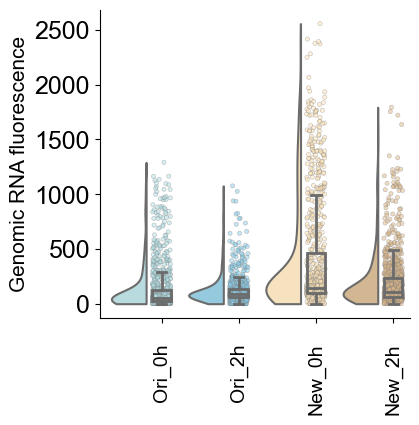

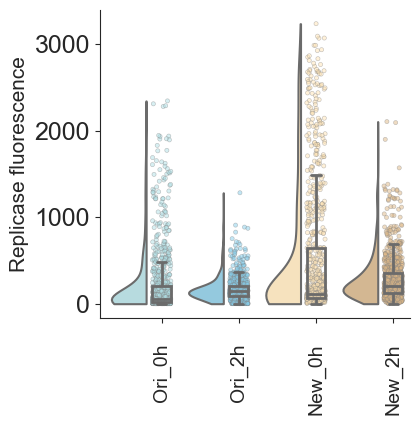

In [8]:
Series = ['Ori_0h', 'Ori_2h', 'New_0h', 'New_2h']
palette = {'Ori_0h': 'powderblue', 'Ori_2h': 'skyblue', 'New_0h': 'moccasin', 'New_2h': 'burlywood'}

d_plot = pd.concat([pd.concat(ds) for ds in ds_dates])

keys = {'Cy3-back': 'Genomic RNA fluorescence',
        'FAM-back': 'Replicase fluorescence'}

for key, ylabel in keys.items():
    fig, ax = plt.subplots(1, 1, figsize=(4,4))
    pt.RainCloud(data=d_plot, x='Series', y=key, order=Series, palette=palette, hue='Series',\
                 width_viol=0.9, linewidth= 1.5, bw=0.3, scale='area', box_showfliers=False,width_box=0.24, box_linewidth=2,\
                 point_size=3, rain_linewidth=0.4, rain_alpha=0.5, rain_edgecolor='grey', jitter=0.12 ,ax=ax)
    ax.set_xlim(-0.8, None)
    ax.tick_params(axis='x', pad=15)
    ax.tick_params(axis ='x',labelsize =14), ax.tick_params(axis ='y',labelsize =18)
    ax.set_xlabel(None), ax.set_ylabel(ylabel, fontsize=15)
    plt.xticks(rotation=90)
    arrange_axis()
    fig.savefig('RNA_Replicase_diffusion_data/Figs/RNA_Rep_diffusion_'+key+'.svg', bbox_inches='tight')
plt.show()

### Top 20% fluorescence fraction (T20)

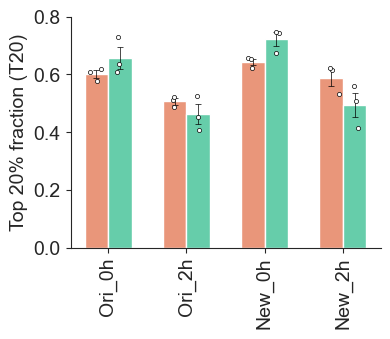

In [10]:
# T20 is the fraction of total fluorescence contained in the brightest 20% of droplets. 
# Complete homogenization gives a theoretical T20 of 0.2.
keys = ['Cy3-back', 'FAM-back']
top = 0.2
T20_set = []
for key in keys:
    T20_condition = []
    for d in ds_dates:
        T20_date = []
        for i in range(3):
            FI = d[i][key]
            top20 = FI.sort_values(ascending=False)[:int(len(FI)*top)]    
            T20 = np.sum(top20)/np.sum(FI)
            T20_date.append(T20)
        T20_condition.append(np.array(T20_date))
    T20_set.append(T20_condition)
    
T20_mean_set = [[np.mean(T20_date) for T20_date in T20_condition] for T20_condition in T20_set]
T20_se_set = [[np.std(T20_date, ddof=1)/np.sqrt(len(T20_date)) for T20_date in T20_condition] for T20_condition in T20_set]

error_bar_set = dict(lw = 0.5, capthick = 0.5, capsize = 2)
shift = 0.3
cols = ['darksalmon', 'mediumaquamarine']

fig = plt.figure(figsize=(4,3))
ax2 = fig.add_subplot(1,1,1) 
x_position = np.arange(len(T20_mean_set[0]))
ax2.bar(x_position -shift/2, T20_mean_set[0], width=0.3, yerr=T20_se_set[0], error_kw=error_bar_set, label='Genomic RNA', color = cols[0])
ax2.bar(x_position + shift/2, T20_mean_set[1], width=0.3, yerr=T20_se_set[1], error_kw=error_bar_set, label='Replicase', color= cols[1])

rng = np.random.default_rng(3)
jit=0.03
jit_1 = list(itertools.chain.from_iterable([[x-shift/2 + rng.normal(0, jit) for j in range(3)] for x in range(4)]))
jit_2 = list(itertools.chain.from_iterable([[x+shift/2 + rng.normal(0, jit) for j in range(3)] for x in range(4)]))
ax2.plot(np.array(jit_1),np.hstack(T20_set[0]),'o', c='w',mec='k',mew =0.5, markersize=3,clip_on=True, zorder=10)
ax2.plot(np.array(jit_2),np.hstack(T20_set[1]),'o', c='w',mec ='k', mew=0.5, markersize=3,clip_on=True, zorder=10)
    
ax2.tick_params(axis='x', labelsize=14),ax2.tick_params(axis='y', labelsize=14)
ax2.set_ylabel('Top 20% fraction (T20)', fontsize = 14)
ax2.set_ylim(0,0.8)
ax2.set_xticks(x_position)
ax2.set_xticklabels(Series)
plt.xticks(rotation=90)
arrange_axis()
fig.savefig('RNA_Replicase_diffusion_data/Figs/RNA_Rep_diffusion_T20.svg', bbox_inches='tight')
plt.show()

### Degree of homogenization (H), calculation

In [12]:
# The degree of homogenization is calculated as H = (T20(0 h) - T20(2 h)) / (T20(0 h) - 0.2)
# H_obs: observed homogenization
# H_coa: homogenization expected from droplet coalescence alone
 
# Calculate T20
def calc_T20(x, top=0.2):
    x = np.array(x)
    x_top = np.sort(x)[::-1][:int(len(x)*top)]
    return np.sum(x_top) / np.sum(x)

FAM_H_obs_set_all = []
Cy3_H_obs_set_all = []
FAM_H_coa_set_all = []
Cy3_H_coa_set_all = []

rng_sim = np.random.default_rng(0)

for j in range(2): # Original or new droplets
    FAM_H_obs_set = []
    Cy3_H_obs_set = []
    FAM_H_coa_set = []
    Cy3_H_coa_set = []
    for k in range(3): # Independent experiments
        d1 = ds_dates[j*2][k] # 0 h
        d2 = ds_dates[j*2+1][k] # 2 h
        
        vol_mean_before = np.mean(d1['Volume (fL)'])
        vol_mean_after = np.mean(d2['Volume (fL)'])
        
        # Observed H
        # FAM: Replicase
        FAM_T20_0h = calc_T20(d1['FAM-back'])
        FAM_T20_2h = calc_T20(d2['FAM-back'])
        FAM_H_obs  = (FAM_T20_0h - FAM_T20_2h) / (FAM_T20_0h - 0.2)
        # Cy3: Genomic RNA
        Cy3_T20_0h = calc_T20(d1['Cy3-back'])
        Cy3_T20_2h = calc_T20(d2['Cy3-back'])
        Cy3_H_obs  = (Cy3_T20_0h - Cy3_T20_2h) / (Cy3_T20_0h - 0.2)
        FAM_H_obs_set.append(FAM_H_obs)
        Cy3_H_obs_set.append(Cy3_H_obs)
        
        # Simulate homogenization caused by droplet coalescence alone
        if vol_mean_after <= vol_mean_before:
            print('No increase in mean volume; H_coa = 0')
            FAM_H_coas = [0] * 100
            Cy3_H_coas = [0] * 100        
        else:
            FAM_H_coas = []
            Cy3_H_coas = []
            for sim in range(100):
                vol = np.array(d1['Volume (fL)'])
                Fl = np.array(d1['FAM-back'])
                Cy3 = np.array(d1['Cy3-back'])
                while np.mean(vol) < vol_mean_after:
                    i1, i2 = rng_sim.choice(len(vol), 2, replace=False)
                    V1, V2 = vol[i1], vol[i2]
                    new_vol = V1 + V2
                    new_Fl = (Fl[i1]*V1 + Fl[i2]*V2) / new_vol
                    new_Cy3 = (Cy3[i1]*V1 + Cy3[i2]*V2) / new_vol
                    
                    vol[i1] = new_vol
                    Fl[i1] = new_Fl
                    Cy3[i1] = new_Cy3
                    
                    vol = np.delete(vol, i2)
                    Fl = np.delete(Fl, i2)
                    Cy3 = np.delete(Cy3, i2)
                
                FAM_T20_coa = calc_T20(Fl)
                FAM_H_coa = (FAM_T20_0h - FAM_T20_coa) / (FAM_T20_0h - 0.2)
                Cy3_T20_coa = calc_T20(Cy3)
                Cy3_H_coa = (Cy3_T20_0h - Cy3_T20_coa) / (Cy3_T20_0h - 0.2)
                FAM_H_coas.append(FAM_H_coa)
                Cy3_H_coas.append(Cy3_H_coa)       
        FAM_H_coa_set.append(FAM_H_coas)
        Cy3_H_coa_set.append(Cy3_H_coas)

    FAM_H_obs_set_all.append(FAM_H_obs_set) 
    Cy3_H_obs_set_all.append(Cy3_H_obs_set)
    FAM_H_coa_set_all.append(FAM_H_coa_set) 
    Cy3_H_coa_set_all.append(Cy3_H_coa_set) 

### Degree of homogenization (H), visualization

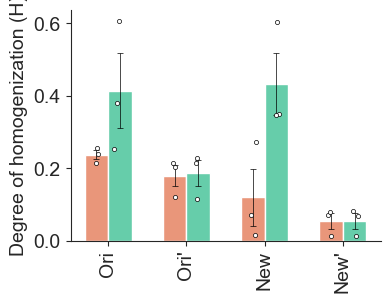

In [14]:
# Mean H_coa across 100 simulations for each independent experiment
Cy3_H_coa_means = [[np.mean(H) for H in Hs] for Hs in Cy3_H_coa_set_all]
FAM_H_coa_means = [[np.mean(H) for H in Hs] for Hs in FAM_H_coa_set_all]

# Combine observed and coalescence-dependent H values
Cy3_H_set = [Cy3_H_obs_set_all[0], Cy3_H_coa_means[0], Cy3_H_obs_set_all[1], Cy3_H_coa_means[1]]
FAM_H_set = [FAM_H_obs_set_all[0], FAM_H_coa_means[0], FAM_H_obs_set_all[1], FAM_H_coa_means[1]]
H_set = [Cy3_H_set, FAM_H_set] # Genomic RNA, replicase

H_mean_set = [[np.mean(H) for H in H_condition] for H_condition in H_set]
H_se_set = [[np.std(H, ddof=1)/np.sqrt(len(H)) for H in H_condition] for H_condition in H_set]

fig = plt.figure(figsize=(4,3))
ax3 = fig.add_subplot(1,1,1) 
x_position = np.arange(len(H_mean_set[0]))
ax3.bar(x_position -shift/2, H_mean_set[0], width=0.3, yerr=H_se_set[0], error_kw=error_bar_set, label='Genomic RNA', color = cols[0])
ax3.bar(x_position + shift/2, H_mean_set[1], width=0.3, yerr=H_se_set[1], error_kw=error_bar_set, label='Replicase', color= cols[1])

rng = np.random.default_rng(0)
jit=0.03
jit_1 = list(itertools.chain.from_iterable([[x-shift/2 + rng.normal(0, jit) for j in range(3)] for x in range(4)]))
jit_2 = list(itertools.chain.from_iterable([[x+shift/2 + rng.normal(0, jit) for j in range(3)] for x in range(4)]))
ax3.plot(np.array(jit_1),np.hstack(H_set[0]),'o', c='w',mec='k',mew =0.5, markersize=3,clip_on=True, zorder=10)
ax3.plot(np.array(jit_2),np.hstack(H_set[1]),'o', c='w',mec ='k', mew=0.5, markersize=3,clip_on=True, zorder=10)
    
ax3.tick_params(axis='x', labelsize=14),ax3.tick_params(axis='y', labelsize=14)
ax3.set_ylabel('Degree of homogenization (H)', fontsize = 14)
ax3.set_xticks(x_position)
ax3.set_xticklabels(['Ori', "Ori'", 'New' ,"New'"])
plt.xticks(rotation=90)
arrange_axis()
fig.savefig('RNA_Replicase_diffusion_data/Figs/RNA_Rep_diffusion_H.svg', bbox_inches='tight')
plt.show()